## Climatology Comparison
In this notebook we compare the climatology of atmospheric blocking with ad without the activation of detection filters

In [2]:
import numpy as np
import numpy.ma as ma
import xarray as xr
import cartopy.crs as ccrs
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.pyplot as plt
from tqdm import tqdm

#my own classes
import sys
sys.path.append("/Users/michelefilippucci/Prog/github/blocktrack/lib")
import blocktoolbox as BT

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


In [3]:
!ls /Users/michelefilippucci/Data/ERA5/

ERA5_2.5x2.5_zg500_daily_1940-2024.nc
ERA5_clim_snowc_0.1x0.1_1980-2000.nc
ERA5_geopotential_day_2.5x2.5_500hPa_1950-2021.nc
ERA5_northem_2.5x2.5_zg500_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg500_daily_1950-1960.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_mergradfilt_md600_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_mergradfilt_md600_daily_1950-1960.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_mergradfilt_md600_daily_djf_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_mergradfilt_md600_daily_jja_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_DAV_tracked_unfilt_daily_1950-1960.nc
ERA5_northem_2.5x2.5_zg_HGHA_tracked_mergradfilt_md600_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_HGHA_tracked_mergradfilt_md600_daily_1950-1960.nc
ERA5_northem_2.5x2.5_zg_HGHA_tracked_mergradfilt_md600_daily_djf_1940-2023.nc
ERA5_northem_2.5x2.5_zg_HGHA_tracked_unfilt_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg_HGHA_tracked_unfilt_daily_1950-1960.nc
ERA5_no

In [5]:
#LOADING DATASET
ds = xr.load_dataset('/Users/michelefilippucci/Data/ERA5/ERA5_northem_2.5x2.5_zg_HGHA_tracked_mergradfilt_md600_daily_1940-2023.nc')
ds2 = xr.load_dataset('/Users/michelefilippucci/Data/ERA5/ERA5_northem_2.5x2.5_zg_DAV_tracked_mergradfilt_md600_daily_1940-2023.nc')

frequency_base = ds['HGHA_freq']
frequency_filt = ds2['DAV_freq']

lon = ds["lon"].values
lat = ds["lat"].values
zg = ds["zg"].values/9.8

ds.close()

lon = ds["lon"]
lat = ds["lat"]

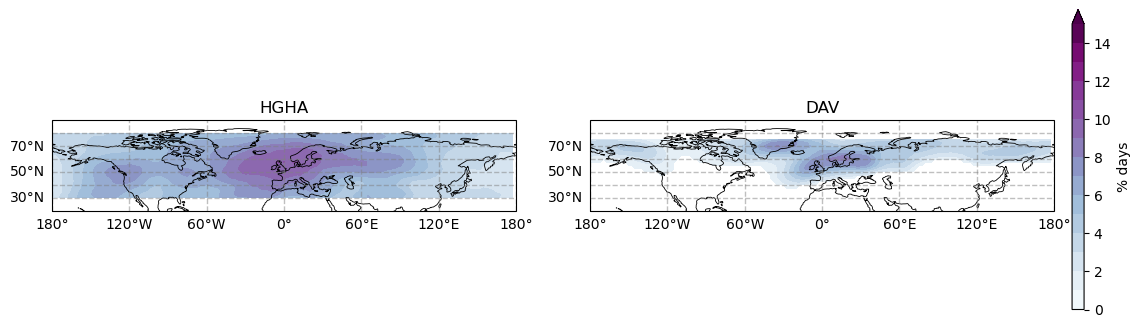

In [7]:
#%matplotlib qt5


fig,ax = plt.subplots(nrows=1,ncols=2,figsize=(12,6),subplot_kw={'projection': ccrs.PlateCarree()})
ax.flatten()
titles = ("HGHA",
         "DAV")
for i,field in enumerate((frequency_base*100,frequency_filt*100)):
    field = ma.masked_array(field,field<1)
    extent =[-180,180,20,90]
    ax[i].set_extent(extent, ccrs.PlateCarree())
    ax[i].coastlines(linewidth = 0.6)
    gl = ax[i].gridlines(crs=ccrs.PlateCarree(), draw_labels=True,
                    linewidth=1, 
                    color='gray', 
                    alpha=0.5, 
                    linestyle='--')

    gl.top_labels=False
    gl.right_labels=False
    cont = ax[i].contourf(lon,lat,field,
                          np.arange(0,16,1),
                          extent=[0,90,-180,180],
                          extend = 'max',
                          cmap = "BuPu")
    ax[i].set_title(titles[i])

fig.subplots_adjust(top=0.88,
bottom=0.1,
left=0.065,
right=0.9,
hspace=0.2,
wspace=0.16)

cbar_ax = fig.add_axes([0.915,0.25,0.01,0.5])
cbar = plt.colorbar(cont, cax=cbar_ax, orientation='vertical',label="% days",pad=0.08, aspect=60)

plt.show()
#plt.savefig("/Users/michelefilippucci/Pictures/PLOTS/climatology.png",dpi = 400)

